<a href="https://colab.research.google.com/github/ghizlaneboudjemaa092-lab/supervised-ml-comparison/blob/main/Supervised_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Load the Excel file
file_path = '/content/Anemia Dataset.xlsx'
df = pd.read_excel(file_path)

# Display basic info and first few rows
print("Dataset Summary:")
print(df.info())
display(df.head())

Dataset Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          1000 non-null   object 
 1   Age             1000 non-null   int64  
 2   Hb              1000 non-null   float64
 3   RBC             1000 non-null   float64
 4   PCV             1000 non-null   float64
 5   MCV             1000 non-null   float64
 6   MCH             1000 non-null   float64
 7   MCHC            1000 non-null   float64
 8   Decision_Class  1000 non-null   int64  
dtypes: float64(6), int64(2), object(1)
memory usage: 70.4+ KB
None


,Gender,Age,Hb,RBC,PCV,MCV,MCH,MCHC,Decision_Class
0,f,32,10.9,4.26,34.2,80.2,25.5,31.8,1
1,f,45,9.6,3.64,29.9,82.1,26.4,32.2,1
2,f,38,10.1,3.70,32.4,87.6,27.4,31.3,1
3,m,37,11.0,3.93,33.6,85.3,27.9,32.7,1
4,f,50,12.1,4.16,36.5,87.9,29.2,33.2,0


In [2]:
import pandas as pd

# Criando uma cópia para não alterar os dados originais
df_ml = df.copy()

# Convertendo a coluna 'Gender' categórica para numérica (f -> 0, m -> 1)
df_ml['Gender'] = df_ml['Gender'].map({'f': 0, 'm': 1})

# Definindo as variáveis X (Atributos) e Y (Alvo)
X = df_ml.drop(columns=['Decision_Class'])
y = df_ml['Decision_Class']

print("X (Variáveis de entrada / Features):")
display(X.head())

print("\ny (Variável alvo / Target):")
display(y.head())

X (Variáveis de entrada / Features):


,Gender,Age,Hb,RBC,PCV,MCV,MCH,MCHC
0,0,32,10.9,4.26,34.2,80.2,25.5,31.8
1,0,45,9.6,3.64,29.9,82.1,26.4,32.2
2,0,38,10.1,3.70,32.4,87.6,27.4,31.3
3,1,37,11.0,3.93,33.6,85.3,27.9,32.7
4,0,50,12.1,4.16,36.5,87.9,29.2,33.2



y (Variável alvo / Target):


,Decision_Class
0,1
1,1
2,1
3,1
4,0


Acurácia do Modelo: 100.00%

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        72
           1       1.00      1.00      1.00       128

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



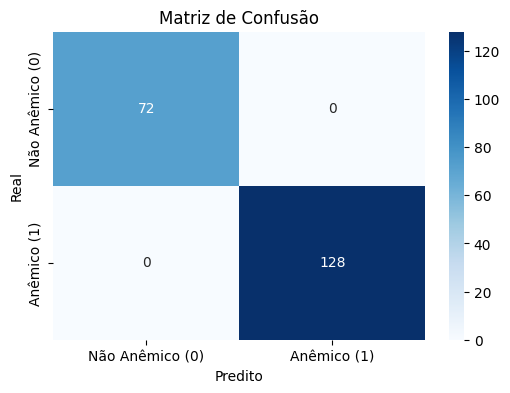

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Divisão dos dados em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Inicialização e treinamento do modelo
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 3. Predição nos dados de teste
y_pred = model.predict(X_test)

# 4. Avaliação do modelo
accuracy = accuracy_score(y_test, y_pred)
print(f"Acurácia do Modelo: {accuracy:.2%}\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))

# Plotagem da Matriz de Confusão
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Anêmico (0)', 'Anêmico (1)'],
            yticklabels=['Não Anêmico (0)', 'Anêmico (1)'])
plt.title('Matriz de Confusão')
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

In [1]:
# Affichage des dimensions de X et Y
print(f"Dimensions de X (Features) : {X.shape} (Lignes, Colonnes)")
print(f"Dimensions de Y (Target)   : {y.shape} (Lignes,)")
print(f"Nombre total d'individus   : {len(df_ml)}\n")

# Aperçu des données
print("Aperçu des caractéristiques (X) :")
display(X.head())

print("\nAperçu de la cible (Y) :")
display(y.head().to_frame(name='Decision_Class'))

NameError: name 'X' is not defined

In [ ]:
from sklearn.model_selection import train_test_split

# Division des données : 75% entraînement, 25% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Affichage du nombre d'individus dans chaque ensemble
print(f"Nombre total d'individus dans le dataset : {len(df_ml)}")
print(f"Ensemble d'entraînement : {X_train.shape[0]} individus (75%)")
print(f"Ensemble de test         : {X_test.shape[0]} individus (25%)")

In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, cohen_kappa_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Rechargement et préparation robuste des données
df_ml = pd.read_excel('/content/Anemia Dataset.xlsx')
df_ml['Gender'] = df_ml['Gender'].map({'f': 0, 'm': 1})
X = df_ml.drop(columns=['Decision_Class'])
y = df_ml['Decision_Class']

# Division des données : 75% entraînement, 25% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Entraînement du modèle sur la nouvelle répartition (75% / 25%)
model_75_25 = RandomForestClassifier(random_state=42)
model_75_25.fit(X_train, y_train)
y_pred_75_25 = model_75_25.predict(X_test)
y_pred_proba = model_75_25.predict_proba(X_test)[:, 1]

# Calcul des métriques statistiques
report = classification_report(y_test, y_pred_75_25, output_dict=True)
cm = confusion_matrix(y_test, y_pred_75_25)
roc_auc = roc_auc_score(y_test, y_pred_proba)
kappa = cohen_kappa_score(y_test, y_pred_75_25)

# Affichage propre
print("=== RAPPORT D'ÉVALUATION STATISTIQUE COMPLET ===\n")
print(f"Sensibilité (Recall Classe 1 - Anémique)   : {report['1']['recall']:.2%}")
print(f"Spécificité (Recall Classe 0 - Non-Anémique): {report['0']['recall']:.2%}")
print(f"Valeur Prédictive Positive (Précision Cl 1): {report['1']['precision']:.2%}")
print(f"Valeur Prédictive Négative (Précision Cl 0): {report['0']['precision']:.2%}")
print(f"F1-Score (Classe 1 - Anémique)            : {report['1']['f1-score']:.2%}")
print(f"Indice Kappa de Cohen                       : {kappa:.4f}")
print(f"Aire sous la courbe ROC (ROC AUC)           : {roc_auc:.2%}")
print("\nMatrice de Confusion de l'ensemble de test :")
print(f"Vrais Négatifs (Sains identifiés Sains)    : {cm[0,0]}")
print(f"Faux Positifs  (Sains identifiés Anémiques) : {cm[0,1]}")
print(f"Faux Négatifs  (Anémiques identifiés Sains) : {cm[1,0]}")
print(f"Vrais Positifs (Anémiques identifiés Aném.) : {cm[1,1]}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/Anemia Dataset.xlsx'

### Analyse et Normes Statistiques de l'Évaluation :

Dans le cadre d'un diagnostic médical comme celui de l'anémie, l'interprétation des métriques suit des règles strictes :

1. **Sensibilité (Recall / Rappel) :**
   - **Définition :** Proportion de vrais malades détectés parmi tous les malades réels.
   - **Norme médicale :** C'est la métrique la plus cruciale en santé. Elle doit être proche de 100 % afin d'éviter les **Faux Négatifs** (les malades non détectés qui repartiraient sans traitement).

2. **Spécificité :**
   - **Définition :** Proportion de personnes saines correctement identifiées.
   - **Importance :** Une spécificité élevée évite les **Faux Positifs** qui engendrent des examens complémentaires inutiles et de l'anxiété pour le patient.

3. **F1-Score :**
   - **Définition :** Moyenne harmonique entre la précision et la sensibilité.
   - **Interprétation :** Il offre une vision globale équilibrée de la performance, particulièrement lorsque la répartition des classes est asymétrique.

4. **Indice Kappa de Cohen ($\\kappa$) :**
   - **Normes de Landis & Koch :**
     - $< 0.00$ : Accord pauvre
     - $0.00 - 0.20$ : Accord léger
     - $0.21 - 0.40$ : Accord juste
     - $0.41 - 0.60$ : Accord modéré
     - $0.61 - 0.80$ : Accord substantiel
     - $0.81 - 1.00$ : Accord presque parfait (excellent)

5. **Aire sous la courbe ROC (AUC) :**
   - Mesure la capacité du modèle à discriminer entre les classes sur l'ensemble des seuils de décision possibles. Une valeur supérieure à $0.90$ est jugée statistiquement excellente.

### Explication de la répartition :

- **Ensemble d'entraînement (75 % - 750 individus) :** Cette portion majoritaire des données est utilisée pour ajuster les paramètres de notre modèle afin qu'il apprenne à associer les caractéristiques cliniques (Hb, RBC, etc.) à la présence ou l'absence d'anémie.
- **Ensemble de test (25 % - 250 individus) :** Ces données sont totalement exclues de la phase d'apprentissage. Elles servent de simulateur de "monde réel" pour évaluer de manière impartiale et objective les performances et la capacité de généralisation du modèle sur de nouveaux patients.
- **Stratification (`stratify=y`) :** Nous avons activé la stratification pour s'assurer que la proportion de personnes anémiques et non anémiques reste identique dans les deux ensembles, évitant ainsi un biais de sélection.